<!-- d2l:prose id=moe-md-1 fw=all -->

# Mixture of Experts (MoE)

In a dense Transformer (that section), every token uses every parameter: doubling model capacity $N \approx 12 L d^2$ doubles the training cost ($6 N$ FLOPs/token) and doubles the inference compute ($2 N$ FLOPs/token). Can we grow a model's stored parameter capacity $N_{\textrm{total}}$ without growing the active parameters $N_{\textrm{active}}$ executed per token?

Recall from that section that the feed-forward network holds two-thirds of a dense block's parameters ($8 d^2$ out of $12 d^2$) and acts **position-wise** on each token vector $\mathbf{x} \in \mathbb{R}^d$ independently. A **Sparse Mixture-of-Experts (MoE)** layer [@Jacobs.Jordan.Nowlan.ea.1991; @Shazeer.Mirhoseini.Maziarz.ea.2017; @Lepikhin.Lee.Xu.ea.2021; @fedus2022switch] exploits this independence (the figure): it replaces a block's single FFN with a bank of $E$ parallel FFN **experts** $\{\textrm{FFN}_1, \dots, \textrm{FFN}_E\}$ and uses a lightweight linear **router** $\mathbf{W}_r \in \mathbb{R}^{d \times E}$ to dispatch each token $\mathbf{x}$ to only its top-$k$ experts ($1 \le k \ll E$).

In [1]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

<!-- d2l:prose id=moe-md-2 fw=all -->

## Conditional Computation: Stored vs. Active Parameters

In an $L$-layer MoE Transformer where each block has attention parameters $P_{\textrm{attn}}$, $E$ routed SwiGLU experts of intermediate width $w$ ($P_{\textrm{exp}} = 3 d w$ parameters per expert), and $E_{\textrm{shared}}$ always-active shared experts [@Dai.Deng.Zhao.ea.2024], all $E + E_{\textrm{shared}}$ experts must be stored in memory ($N_{\textrm{total}}$), but each token executes only $k + E_{\textrm{shared}}$ experts ($N_{\textrm{active}}$):

In [2]:
def moe_accounting(name, d, width, num_experts, num_active, num_layers,
                   shared=0, unit=1e9):
    """Expert parameters stored, and expert and router parameters active
    per token, in a stack of SwiGLU expert layers."""
    per_expert = 3 * d * width          # SwiGLU: three d x width matrices
    store = num_layers * (num_experts + shared) * per_expert
    active = num_layers * ((num_active + shared) * per_expert
                           + d * num_experts)      # + the router
    tag = 'B' if unit == 1e9 else 'M'
    print(f'{name:>12}: {store/unit:5.3g}{tag} in experts, '
          f'{active/unit:5.3g}{tag} active per token, '
          f'ratio {store/active:4.1f}x')
    return store, active

moe_accounting('ours', 128, 341, 8, 1, 2, unit=1e6)
moe_accounting('DeepSeek-V3', 7168, 2048, 256, 8, 58, shared=1)
store, active = moe_accounting('Mixtral 8x7B', 4096, 14336, 8, 2, 32)
attn = 32 * (2 * 4096 * 4096 + 2 * 4096 * 1024)  # GQA: 32 Q, 8 KV heads
emb = 2 * 32000 * 4096                           # embedding + output head
print(f'{"":>12}  with attention and embeddings: '
      f'{(store + attn + emb)/1e9:.1f}B stored, '
      f'{(active + attn + emb)/1e9:.1f}B active')

        ours:   2.1M in experts, 0.264M active per token, ratio  7.9x
 DeepSeek-V3:   656B in experts,  23.1B active per token, ratio 28.4x
Mixtral 8x7B:  45.1B in experts,  11.3B active per token, ratio  4.0x
              with attention and embeddings: 46.7B stored, 12.9B active


<!-- d2l:prose id=moe-md-3 fw=all -->

Notice how $N_{\textrm{total}}$ and $N_{\textrm{active}}$ govern different system resources:

- **Per-token FLOPs (training and prefill)** scale with **$N_{\textrm{active}}$** ($C_{\textrm{train}} \approx 6 N_{\textrm{active}} D$).
- **VRAM capacity** scales with **$N_{\textrm{total}}$**, because all $E$ experts must reside in device memory.
- **Batched decode bandwidth:** At batch size $B = 1$, a token streams only $k$ experts from HBM ($N_{\textrm{active}}$ weight bytes). Across a batch of $B$ tokens, however, different tokens activate different experts: once $B \gg E / k$, almost all $E$ experts are touched by at least one token in the batch, so each decode step streams nearly **$N_{\textrm{total}}$** weight bytes from HBM while performing $2 B N_{\textrm{active}}$ FLOPs.

## A Mixture-of-Experts Layer

### Top-$k$ Routing

For each token $\mathbf{x} \in \mathbb{R}^d$, the router computes probabilities $\mathbf{p}(\mathbf{x}) = \textrm{softmax}(\mathbf{x}\mathbf{W}_r) \in \Delta^{E-1}$, selects the set $T(\mathbf{x}) \subset \{1, \dots, E\}$ of $k$ highest-scoring experts, keeps their raw probabilities as weights, $g_e(\mathbf{x}) = p_e(\mathbf{x})$ (renormalizing them over $T(\mathbf{x})$ would leave a top-1 router without a gradient; Exercise 1), and forms the weighted sum:

$$
\textrm{MoE}(\mathbf{x}) \;=\; \sum_{e \in T(\mathbf{x})} g_e(\mathbf{x}) \, \textrm{FFN}_e(\mathbf{x}).
$$

![A mixture-of-experts layer with eight experts, two of which are active per token. The router scores every expert. The two most probable experts run, and their outputs are weighted by their probabilities and added. The other six experts are stored but do no work for this token.](../img/mdl-transformers-moe.svg)

### Dispatching Tokens to Fixed-Capacity Expert Buffers

In compiled or distributed training, each expert $e \in \{1, \dots, E\}$ pre-allocates a fixed buffer of capacity $S = \lceil \gamma \cdot n k / E \rceil$ slots for a batch of $n$ tokens, where $n k / E$ is the perfectly balanced load per expert and $\gamma \ge 1$ is the **capacity factor** ($\gamma = E$ disables dropping by setting $S = n k$). If more than $S$ token--expert assignments target expert $e$, the excess assignments are **dropped** (contributing zero to the equation, so those tokens pass through the surrounding block's residual skip connection). the figure follows six tokens through this dispatch.

![Dispatching six tokens to four experts, top-2 each, with capacity factor $\gamma = 1.25$, so $S = 4$ slots per expert. Assignments queue per expert in token order. The fifth and sixth assignments to expert 1 fall past its $S$ slots and are dropped, so tokens 5 and 6 get only their second expert. A token whose every assignment is dropped keeps only its residual.](../img/mdl-transformers-moe-capacity.svg)

`MoELayer` implements the router, the dispatch into buffers of $S$ slots, and the drop rule:

In [3]:
class MoELayer(nn.Module):
    """Token-choice top-k mixture of SwiGLU d2l.FeedForward experts, each
    with a buffer of S = capacity_factor * n k / E slots for n tokens."""
    def __init__(self, num_hiddens, num_experts, num_active,
                 capacity_factor=1.25):
        super().__init__()
        self.num_experts, self.num_active = num_experts, num_active
        self.capacity_factor = capacity_factor
        self.router = nn.Linear(num_hiddens, num_experts, bias=False)
        self.experts = nn.ModuleList([d2l.FeedForward(num_hiddens)
                                      for _ in range(num_experts)])
        # Added to the probabilities for the selection only; zero until a
        # balancing method moves it
        self.register_buffer('expert_bias', torch.zeros(num_experts))
        # Assignments per expert, dropped or not, and the dropped ones,
        # counted by record() until reset_stats()
        self.register_buffer('load', torch.zeros(num_experts))
        self.register_buffer('dropped', torch.zeros(()))

    def forward(self, X):
        x = X.reshape(-1, X.shape[-1])                 # (n, d): the tokens
        (n, d), E, k = x.shape, self.num_experts, self.num_active
        S = math.ceil(self.capacity_factor * n * k / E)  # slots per expert
        P = F.softmax(self.router(x), -1)              # (n, E)
        idx = (P + self.expert_bias).topk(k).indices   # (n, k)
        e = idx.flatten()                              # expert of each pair
        onehot = F.one_hot(e, E)                       # (n k, E)
        rank = (onehot.cumsum(0) * onehot).sum(1) - 1  # place in its queue
        slot = torch.where(rank < S, e * S + rank, E * S)  # E S: dropped
        buf = x.new_zeros(E * S + 1, d)                # + an overflow row
        buf[slot] = x.repeat_interleave(k, 0)
        Y = self.run_experts(buf[:-1].reshape(E, S, d)).reshape(E * S, d)
        Y = torch.cat([Y, Y.new_zeros(1, d)])[slot]    # dropped: zeros
        weights = P.gather(-1, idx)                    # (n, k): the p_i
        out = (weights[..., None] * Y.reshape(n, k, d)).sum(1)
        self.record(onehot.sum(0), (rank >= S).sum(), P)
        return out.reshape(X.shape)

    def run_experts(self, H):
        """Each expert's SwiGLU on its own buffer: (E, S, d) -> (E, S, d)."""
        W = lambda name: torch.stack(  # (E, d_in, d_out): one per expert
            [getattr(e, name).weight for e in self.experts]).mT
        return (F.silu(H @ W('W_g')) * (H @ W('W_1'))) @ W('W_2')

    def record(self, counts, num_dropped, P):
        """Add a batch's assignments per expert and drops to the totals,
        and keep its balancing loss, a measure of imbalance."""
        self.load += counts
        self.dropped += num_dropped
        f = counts / counts.sum()                      # this batch's shares
        self.aux_loss = self.num_experts * (f * P.mean(0)).sum()

    def reset_stats(self):
        self.load.zero_()
        self.dropped.zero_()

<!-- d2l:prose id=moe-md-4 fw=all -->

Two small utilities, `moe_layers(model)` and `active_params(model)`, collect all `MoELayer` submodules in a network and tally how many parameters participate in the forward pass of a single token ($k / E$ of the expert bank plus all shared parameters):

In [4]:
def moe_layers(model):
    """The MoELayer modules of a model."""
    return [m for m in model.modules() if isinstance(m, MoELayer)]

def active_params(model):
    """Parameters used per token: all but the unselected experts."""
    return d2l.num_params(model) - sum(
        d2l.num_params(l.experts) * (l.num_experts - l.num_active)
        // l.num_experts for l in moe_layers(model))

<!-- d2l:prose id=moe-md-5 fw=all -->

Because `d2l.TransformerBlock` (that section) accepts an `ffn_factory` hook, replacing the dense FFN with an 8-expert Top-2 `MoELayer` requires passing a single lambda:

In [5]:
blk = d2l.TransformerBlock(256, num_heads=8,
                           ffn_factory=lambda: MoELayer(256, 8, 2))
X = torch.randn(4, 100, 256)
d2l.check_shape(blk(X), X.shape)  # The expert layer fits into the block
moe = MoELayer(256, num_experts=8, num_active=2)
print(f'{d2l.num_params(moe)} parameters stored, '
      f'{active_params(moe)} active per token')

4198400 parameters stored, 1051136 active per token


<!-- d2l:prose id=moe-md-6 fw=all -->

## Routing Collapse and Load Balancing

### Uneven Load and Positive Feedback

Even at initialization, random router weights send more tokens to some experts than others. During training without a load-balancing mechanism, a **positive-feedback loop** amplifies this asymmetry into **routing collapse** [@Shazeer.Mirhoseini.Maziarz.ea.2017]: whichever experts receive more tokens at step 1 receive larger gradient updates, reduce the language-modeling loss faster on step 2, get rewarded by $\nabla_{\mathbf{W}_r}\mathcal{L}$ with higher router logits on step 3. Left unchecked, the loop can end with a few experts holding most of the top-$k$ slots while the others receive too few tokens to learn anything.

### Two Solutions: Auxiliary Balancing Loss vs. Loss-Free Bias Controller

1. **Switch auxiliary load-balancing loss** [@fedus2022switch]: Let $f_e = \frac{1}{n k} \sum_{t=1}^n \mathbb{I}[e \in T(\mathbf{x}_t)]$ be the empirical fraction of routed slots dispatched to expert $e$ in a batch of $n$ tokens, and let $\bar{p}_e = \frac{1}{n}\sum_{t=1}^n p_e(\mathbf{x}_t)$ be the mean router probability assigned to expert $e$. Adding $\alpha \mathcal{L}_{\textrm{aux}}$ to the training loss, where

   $$
   \mathcal{L}_{\textrm{aux}} \;=\; E \sum_{e=1}^{E} f_e \, \bar{p}_e,
   $$

   penalizes high probability $\bar{p}_e$ on heavily loaded experts (large $f_e$) and achieves its minimum $\mathcal{L}_{\textrm{aux}} = 1$ when $f_e = 1/E$ for all $e$.

2. **Loss-free dynamic router bias control** (@Wang.Gao.Zeng.ea.2024, used in DeepSeek-V3 [@Liu.Feng.Xue.ea.2024]): Because $\nabla \mathcal{L}_{\textrm{aux}}$ pushes token representations toward uniform routing even when specialization would lower language-modeling loss, this method balances the load without an auxiliary gradient (DeepSeek-V3 keeps only a very small sequence-wise balance loss next to it). Instead, each expert maintains a non-differentiable selection bias $b_e$ added *only* inside top-$k$ selection ($T(\mathbf{x}) = \textrm{argtop}_k(\mathbf{p}(\mathbf{x}) + \mathbf{b})$, leaving the gating weights $g_e(\mathbf{x})$ unbiased), updated after each step by a sign controller with rate $\eta_b$:

   $$
   b_e \;\leftarrow\; b_e \;+\; \eta_b \, \textrm{sign}\!\left(\frac{1}{E} - f_e\right).
   $$

### Load-Balancing Methods Compared

We add `balance(rate)` to `MoELayer` and compare five configurations on a 2-block byte-level `GPT` ($E = 8, k = 1$, each expert a full-width FFN so the 1 active expert equals 1 dense FFN) over 800 steps on WikiText-103: (1) initialization, (2) no balancing, (3) a **frozen router** control (testing whether collapse requires router--expert feedback), (4) Switch auxiliary loss ($\alpha = 0.01$), and (5) loss-free bias control ($\eta_b = 10^{-2}$):

In [6]:
@d2l.add_to_class(MoELayer)
@torch.no_grad()  # Not a gradient step
def balance(self, rate):
    """The controller: move each bias one step toward the even load, then
    count the next batch's assignments afresh."""
    self.expert_bias += rate * torch.sign(self.load.mean() - self.load)
    self.load.zero_()

def train_moe_lm(model, data, optimizer, num_steps, aux_weight=0.0,
                 bias_rate=0.0):
    """d2l.train_steps with a balancing loss and the bias controller."""
    device = d2l.try_gpu()
    model.to(device)
    layers, losses = moe_layers(model), []
    for l in layers:
        l.reset_stats()
    while len(losses) < num_steps:
        for X, Y in data.train_dataloader():
            ce = F.cross_entropy(model(X.to(device)).flatten(0, 1),
                                 Y.to(device).flatten())
            optimizer.zero_grad()
            (ce + aux_weight * sum(l.aux_loss for l in layers)).backward()
            optimizer.step()
            for l in layers:
                l.balance(bias_rate)
            losses.append(ce.detach())
            if len(losses) == num_steps:
                return torch.stack(losses).tolist()

<!-- d2l:prose id=moe-md-7 fw=all -->

To inspect routing balance on the validation set, `evaluate_moe` records the validation cross-entropy, the sorted per-expert token shares, and the fraction of dropped assignments, while `measure` compares the validation loss at the configured capacity factor against an unclipped buffer ($S = n k$, zero drops):

In [7]:
def evaluate_moe(model, data):
    """Validation loss; each expert layer's shares of the validation
    tokens, busiest expert first; and the fraction of assignments dropped."""
    layers = moe_layers(model)
    for l in layers:
        l.reset_stats()
    loss = math.log(d2l.lm_perplexity(model, data.val_dataloader()))
    shares = [sorted((l.load / l.load.sum()).tolist(), reverse=True)
              for l in layers]
    dropped = sum(float(l.dropped) for l in layers) / sum(
        float(l.load.sum()) for l in layers)
    return loss, shares, dropped

def measure(model, data):
    """The validation loss, the same with buffers that drop nothing, the
    busiest expert's load in units of the even share, and the fraction
    dropped; and the shares."""
    layers = moe_layers(model)
    val, shares, dropped = evaluate_moe(model, data)
    peak = max(l.num_experts * s[0] for l, s in zip(layers, shares))
    capacity = [l.capacity_factor for l in layers]
    for l in layers:  # S = n k slots: room for every assignment
        l.capacity_factor = l.num_experts
    val_all = evaluate_moe(model, data)[0]
    for l, c in zip(layers, capacity):
        l.capacity_factor = c
    return (val, val_all, peak, dropped), shares

<!-- d2l:prose id=moe-md-8 fw=all -->

Next, we load `WikiText103` and define `small_gpt`, a 2-block byte-level `GPT` of width $d = 128$ that uses a dense FFN when `capacity_factor=None` and an 8-expert Top-1 `MoELayer` otherwise, along with `freeze_router` for our frozen-router control arm:

In [8]:
data = d2l.WikiText103(batch_size=64, num_steps=128)

def small_gpt(vocab_size, capacity_factor=None):
    """Two blocks of width 128; with a capacity factor, each feed-forward
    network becomes eight experts with one active per token."""
    experts = lambda: MoELayer(128, 8, 1, capacity_factor=capacity_factor)
    model = d2l.GPT(vocab_size, num_hiddens=128, num_heads=4, num_blks=2,
                    ffn_factory=None if capacity_factor is None else experts)
    return model.to(d2l.try_gpu())

def freeze_router(model):
    """Keep every router at its initial weights: no gradient, no update."""
    for l in moe_layers(model):
        l.router.weight.requires_grad_(False)

<!-- d2l:prose id=moe-md-9 fw=all -->

The driver `balancing_run` trains a fresh `small_gpt` with capacity factor $\gamma = 1.25$ for `num_steps=800` under a chosen balancing regime and returns the `measure` summary:

In [9]:
def balancing_run(data, num_steps=800, frozen=False, aux_weight=0.0,
                  bias_rate=0.0):
    """Measure a fresh small MoE GPT after num_steps steps of training with
    one balancing setting."""
    model = small_gpt(len(data.vocab), capacity_factor=1.25)
    if frozen:
        freeze_router(model)
    if num_steps:
        optimizer = d2l.LMOptimizer(model, lr=2e-3, num_steps=num_steps,
                                    warmup=100)
        train_moe_lm(model, data, optimizer, num_steps, aux_weight,
                     bias_rate)
    return measure(model, data)

<!-- d2l:prose id=moe-md-10 fw=all -->

Running two independent seeds of each of the five balancing arms tabulates their validation losses (with and without buffer drops), peak expert load, and drop rates:

In [10]:
arms = {'initialization': dict(num_steps=0), 'no balancing': {},
        'frozen router': dict(frozen=True),
        'auxiliary loss': dict(aux_weight=0.01),
        'bias controller': dict(bias_rate=0.01)}
print(f'spaces: {(data.val == ord(" ")).mean():.1%} of the validation bytes')
print(f'{"two runs each":>15}  {"loss":^9}  {"no drops":^9}  '
      f'{"busiest":^9}  {"dropped":^7}')
shares = {}  # The first run's shares
for name, kwargs in arms.items():
    (a, shares[name]), (b, _) = [balancing_run(data, **kwargs)
                                 for _ in range(2)]
    print(f'{name:>15}  {a[0]:.2f} {b[0]:.2f}  {a[1]:.2f} {b[1]:.2f}  '
          f'{a[2]:3.1f}x {b[2]:3.1f}x  {a[3]:3.0%} {b[3]:3.0%}')

spaces: 18.9% of the validation bytes
  two runs each    loss     no drops    busiest   dropped


 initialization  5.63 5.49  5.63 5.49  2.5x 2.8x  22% 20%


   no balancing  1.75 1.81  1.70 1.73  3.3x 3.9x  24% 36%


  frozen router  1.71 1.72  1.67 1.67  2.8x 2.1x  14% 17%


 auxiliary loss  1.59 1.54  1.59 1.54  1.3x 1.2x   0%  0%


bias controller  1.58 1.56  1.57 1.55  1.3x 1.5x   0%  2%


<!-- d2l:prose id=moe-md-11 fw=all -->

Plotting the ranked expert token shares averaged across both MoE layers against the uniform $1/8 = 12.5\%$ reference line visualizes how both balancing mechanisms prevent routing collapse:

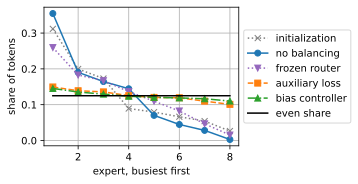

In [11]:
ranks = list(range(1, 9))
mean_shares = [[sum(rank) / len(rank) for rank in zip(*s)]
               for s in shares.values()]  # Mean over the layers
d2l.plot(ranks, mean_shares + [[1 / 8] * 8], 'expert, busiest first',
         'share of tokens', legend=list(shares) + ['even share'],
         fmts=('C7x:', 'C0o-', 'C4v:', 'C1s--', 'C2^-.', 'k-'),
         legend_loc='outside')

<!-- d2l:prose id=moe-md-12 fw=all -->

Without balancing (`no balancing`), the 3 busiest experts capture about $70\%$ of all routed tokens while the idlest receives almost none, and under a capacity factor $\gamma = 1.25$ a quarter to a third of all assignments are dropped. Freezing the router (`frozen router`) ends somewhat less skewed, but the fresh model (`initialization`) is already about as lopsided as the unbalanced one, so at this scale much of the skew comes from the inputs rather than from feedback between expert learning and router updates; two runs per row cannot separate the two (Exercise 3). Both the Switch auxiliary loss and the loss-free bias controller hold every expert near the ideal $1/E = 12.5\%$ share (the busiest below twice it, with at most a few percent dropped at $\gamma = 1.25$).

## Mixture-of-Experts Language Models

### MoE GPT vs. Dense GPT at Matched Active Parameters

Comparing our balanced 8-expert Top-1 MoE GPT ($N_{\textrm{active}} = 0.43\textrm{M}$, $N_{\textrm{total}} = 2.26\textrm{M}$) against a dense GPT with the **exact same active parameters and per-token FLOPs** ($N_{\textrm{active}} = N_{\textrm{total}} = 0.43\textrm{M}$) across 6,000 training steps on WikiText-103 demonstrates the IsoFLOP advantage of sparse conditional capacity:

In [12]:
capacity = {'dense': None, 'MoE': 2}  # The dense model has no buffers
models = {name: small_gpt(len(data.vocab), capacity_factor=c)
          for name, c in capacity.items()}
for name, model in models.items():
    print(f'{name:>5}: {d2l.num_params(model) / 1e6:5.2f}M parameters, '
          f'{active_params(model) / 1e6:.2f}M active per token')

dense:  0.43M parameters, 0.43M active per token
  MoE:  2.26M parameters, 0.43M active per token


<!-- d2l:prose id=moe-md-13 fw=all -->

Training two independent runs of both models for $6{,}000$ steps with the Switch auxiliary loss ($\alpha = 0.01$) and evaluating validation loss every $250$ steps tracks when the sparse model overtakes the dense baseline:

run 1: dense 1.321, MoE 1.277; MoE ahead from step 2000, 0.0% dropped at the end


run 2: dense 1.327, MoE 1.265; MoE ahead from step 750, 0.0% dropped at the end


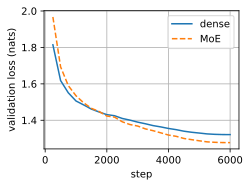

In [13]:
num_steps, every = 6000, 250
curves = {name: [] for name in capacity}  # Validation loss every 250 steps
for run in range(2):
    for name, c in capacity.items():  # Dense first, then MoE
        model = small_gpt(len(data.vocab), capacity_factor=c)
        optimizer = d2l.LMOptimizer(model, lr=2e-3, num_steps=num_steps,
                                    warmup=100)
        curve = []
        for _ in range(num_steps // every):  # Dense: no aux loss to add
            train_moe_lm(model, data, optimizer, every, aux_weight=0.01)
            curve.append(
                math.log(d2l.lm_perplexity(model, data.val_dataloader())))
        curves[name].append(curve)
    dense, moe = curves['dense'][-1], curves['MoE'][-1]
    ahead = next((every * (i + 1) for i, (m, d) in enumerate(zip(moe, dense))
                  if m < d), None)
    print(f'run {run + 1}: dense {dense[-1]:.3f}, MoE {moe[-1]:.3f}; '
          + (f'MoE ahead from step {ahead}, ' if ahead else 'MoE never ahead, ')
          + f'{evaluate_moe(model, data)[2]:.1%} dropped at the end')
d2l.plot(list(range(every, num_steps + 1, every)),
         [curves['dense'][0], curves['MoE'][0]], 'step',
         'validation loss (nats)', legend=['dense', 'MoE'], fmts=('-', '--'))

<!-- d2l:prose id=moe-md-14 fw=all -->

The MoE model starts behind the dense model, overtakes it within the first 2,000 steps, and ends about 0.05 nats lower in validation cross-entropy at the same per-token FLOP cost.

### Fine-Grained and Shared Experts in Released Models

Recent frontier MoE families (the table) refine the coarse 8-expert Top-2 recipe of Mixtral 8x7B in two ways (the figure):

1. **Fine-grained expert segmentation:** Splitting each full-width expert into $m$ narrower experts of width $w / m$ while scaling total experts to $m E \in [128, 256]$ and active experts to $m k \in [4, 8]$ leaves both stored and active parameter counts unchanged, while expanding the number of distinct active expert combinations from $\binom{8}{2} = 28$ to $\binom{256}{8} \approx 4 \times 10^{14}$.
2. **Shared experts** [@Dai.Deng.Zhao.ea.2024]: Dedicating $E_{\textrm{shared}} \ge 1$ narrow experts that execute on *every* token without routing lets shared experts absorb common grammatical and formatting transformations so routed experts can specialize without redundancy.

![Three ways to spend the same expert parameters. Each box is an expert, its width proportional to its size, and the highlighted experts are the ones selected for one token. Top: 16 experts, of which a token uses 2. Middle: the same parameters as 64 experts of a quarter width, of which a token uses 8. Bottom: one of the narrow experts becomes a shared expert that every token uses, and each token selects 7 of the other 63. All three rows store and use the same number of parameters per token.](../img/mdl-transformers-moe-fine.svg)

<!-- tbl-caption:Routed-expert configurations of released MoE language models. -->

| Model | Experts per layer ($E$) | Active $k$ | Expert width / $d$ | Shared expert | Stored / active parameters |
|:--|:--:|--:|--:|:--:|--:|
| Mixtral 8x7B [@Jiang.Sablayrolles.Roux.ea.2024] | 8 | 2 | 3.5 | none | 46.7B / 12.9B = 3.6 |
| DeepSeek-V3 [@Liu.Feng.Xue.ea.2024] | 256 | 8 | 0.29 | 1 | 671B / 37B = 18 |
| Qwen3-235B [@Yang.Li.Yang.ea.2025] | 128 | 8 | 0.38 | none | 235B / 22B = 11 |
| gpt-oss-120b [@OpenAI.2025] | 128 | 4 | 1.0 | none | 117B / 5.1B = 23 |

## Summary

**Mixture-of-Experts (MoE)** layers (the equation) replace a dense FFN with $E$ routed expert FFNs and activate only the top $k \ll E$ experts per token, decoupling **stored parameters $N_{\textrm{total}}$** (memory capacity) from **active parameters $N_{\textrm{active}}$** (per-token FLOPs). Without load balancing, expert utilization is heavily skewed: much of this skew is already present at initialization, and positive feedback between router and experts can amplify it into **routing collapse**, whereas both the **Switch auxiliary loss** $\mathcal{L}_{\textrm{aux}} = E \sum_e f_e \bar{p}_e$ (the equation) and **loss-free dynamic router biases** $b_e \leftarrow b_e + \eta_b \textrm{sign}(1/E - f_e)$ (the equation) hold expert loads near $1/E$. At matched active parameters and training FLOPs, a balanced MoE language model reaches lower validation cross-entropy than a dense GPT. Recent open-weights MoE architectures (the table) further segment experts into **fine-grained** banks ($E \in [128, 256], k \in [4, 8]$) to expand combinatorial specialization, often alongside an always-active **shared expert** (the figure).

## Exercises

1. **Router gradient under $k = 1$ vs. $k > 1$ renormalization.** Many MoE layers renormalize the selected probabilities by their sum: $g_e(\mathbf{x}) = p_e(\mathbf{x}) / \sum_{j \in T(\mathbf{x})} p_j(\mathbf{x})$.
   1. Show that if you apply this same renormalization when $k = 1$, then $g_{e^*}(\mathbf{x}) = p_e(\mathbf{x}) / p_e(\mathbf{x}) \equiv 1$ is constant, so $\partial \textrm{MoE}(\mathbf{x}) / \partial \mathbf{W}_r = \mathbf{0}$ and the router never receives a task-loss gradient.
   2. Verify in code that our `MoELayer` avoids this by weighting each selected expert by its raw probability (so $g_{e^*}(\mathbf{x}) = p_{e^*}(\mathbf{x})$ as in Switch Transformer [@fedus2022switch]).

2. **Minimum and gradient of the Switch auxiliary loss.** Consider $\mathcal{L}_{\textrm{aux}} = E \sum_{e=1}^E f_e \bar{p}_e$ (the equation), where $f_e$ is treated as a stop-gradient constant and $\sum_e \bar{p}_e = 1$.
   1. Compute $\partial \mathcal{L}_{\textrm{aux}} / \partial s_{t,e}$ with respect to token $t$'s router logit $s_{t,e} = (\mathbf{x}_t \mathbf{W}_r)_e$, and show that it vanishes if and only if all empirical loads are equal ($f_1 = \dots = f_E = 1/E$).
   2. Prove via Cauchy--Schwarz that when $\bar{p}_e = f_e$, $\mathcal{L}_{\textrm{aux}} \ge 1$ with equality if and only if $f_e = 1/E$, and find its maximum value $E$ under complete single-expert collapse ($f_1 = \bar{p}_1 = 1$).

3. **Disentangling positive feedback from input distribution skew.** In `balancing_run`, compare the `frozen router` arm against `no balancing` at steps $100, 200, 400, 800$. Starting from the fresh model's top-expert share (already about a third in our byte-level model), does the trainable router's top-expert share move further from it than the frozen router's, over enough seeds to tell, and what happens if you initialize all expert output projections `W_2` to zero so all experts produce identical outputs on early steps?

4. **Step-size dynamics of the loss-free bias controller.** Run `balancing_run` with `bias_rate` $\eta_b \in \{10^{-4}, 10^{-3}, 10^{-2}, 10^{-1}\}$ and plot the top-expert share and validation loss across training steps. Why does an overly large controller step size ($\eta_b = 10^{-1}$) cause expert loads to oscillate from step to step?

5. **Overfitting of MoE in the tiny-data regime.** Repeat the 6,000-step `dense` vs. `MoE` comparison (that section), but restrict `data.train` to only its first $65{,}536$ bytes ($64\textrm{ KB}$) so the models pass over the same text hundreds of times. Plot both training loss and validation loss for `dense` and `MoE`: why does the $2.26\textrm{M}$-parameter MoE memorize the small corpus much faster and start overfitting earlier than the $0.43\textrm{M}$-parameter dense model even though both use the exact same FLOPs per token?

6. **Shared experts and fine-grained granularity at fixed budget.** Implement a `SharedMoELayer` that runs 1 always-active shared expert of width $w$ plus Top-$k$ of $E$ routed experts of width $w$, and compare three FFN configurations inside `small_gpt` at matched stored and active expert width ($16 \times 170$ stored, $2 \times 170$ active per block): (a) coarse $E = 8, k = 1, w = 340$, (b) medium $E = 16, k = 2, w = 170$, and (c) fine + shared $E_{\textrm{shared}} = 1, E = 15, k = 1, w = 170$. Compare their validation losses after 800 steps.

[Discussions](https://d2l.discourse.group/t/36779)